# 17 - Multiple-choice answers as prediction sets

> "Instead of one answer, can Quill show students a shortlist that contains the right answer nine times in ten?" - Quill product lead

The product lead's instinct is sound. A single letter from Quill is right about four times in five on our exam-practice questions, and a student cannot tell which fifth they are in. A shortlist that says "it is one of these two" is more useful to a student than a confident letter that is wrong, provided the shortlist keeps its promise. So the sharper statistical question is: from the probabilities a language model gives the four options, can we build, for every new question, a set of options that contains the answer-key option at least 90% of the time; how many options does that take; and does the 90% hold within each subject, or only on average?

None of this needs new theory. It is notebook 04's recipe, with a language model's option probabilities in the place of a classifier's softmax, which is how Kumar et al. (2023) applied conformal prediction to multiple-choice question answering. What is new is what a hosted language model does to the recipe's inputs: its probabilities are extremely peaked, they are recorded with limited resolution, and some APIs return no probabilities at all.

**What you will learn**

- How to build LAC answer sets from token probabilities, and why a model that is confidently wrong when it is wrong forces the bar down to options it rated at a tenth of a percent.
- Why notebook 04's deterministic APS collapses to "all four options" on these probabilities, and what tied scores do to coverage.
- How to build sets when an API returns no probabilities: agreement among ten sampled answers, plus a tie-breaking jitter that restores near-exact coverage.
- Why 90% overall leaves some subjects far below 90%, and what subject-by-subject calibration costs in set size and in calibration data.

**Where we are in the series.** Notebook 16 introduced Quill, compared the three ways a language model reports certainty (token probability, stated confidence, agreement of samples), and previewed one LAC threshold; this notebook takes that threshold apart and builds the product on it. It leans on notebook 02 (the corrected quantile), notebook 03 (the leaderboard argument and the coverage lottery) and notebook 04 (LAC, APS, class-conditional calibration, the 1/K rule for empty sets). Notebook 18 moves from choosing among four options to long answers, where the unit of a guarantee is a whole explainer.

In [1]:
import math
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
RANDOM_SEED = 20260707
ALPHA = 0.10   # the product's 90% promise

# Series palette: blue = data, green = covered/healthy, amber = calibration/warning,
# red = missed/fault/naive, gray = reference, purple = alternative method.
BLUE, GREEN, AMBER, RED, GRAY, PURPLE = (
    "#2563EB", "#059669", "#F59E0B", "#DC2626", "#6B7280", "#7C3AED",
)

## 1. From triage teams to answer options

Notebook 04 built shortlists of care teams in three steps, and we only recap them here. First, score each calibration case by one minus the probability the model gave the true label: the LAC score. Second, take the corrected quantile of those scores from notebook 02 (field guide §1), `q_hat`. Third, for a new case, keep every label whose probability is at least `1 - q_hat`. Notebook 04 called `q_hat` itself the bar; in this notebook the word means `1 - q_hat` only, the probability an option needs to make the shortlist, so a low bar is a long shortlist. APS replaced the score with the probability mass stacked from the most likely label down to the true one, and class-conditional (Mondrian) calibration gave each group its own bar when one shared bar left a group behind. The coverage argument never asked what the model was; it asked only that calibration cases and new cases be exchangeable (notebook 03).

Here the classifier is `gpt-4.1-mini`, the labels are the letters A to D, and the softmax is the token probability of each answer letter: the probability of the first answer token, read from the log-probabilities at temperature 0 and renormalized over the four letters (notebook 16). The recipe does not care that the model writes text. It does care that the procedure behind the probabilities (model version, prompt, decoding settings, option order) is the one we calibrate and the one we deploy (field guide §25), and that the calibration questions look like the questions students will ask (field guide §26). We load the cached outputs and look at what the recipe will be fed.

In [2]:
questions = pd.read_csv("llm_data/mmlu_questions.csv")
outputs = pd.read_csv("llm_data/mmlu_llm_outputs.csv")
mmlu = questions.merge(outputs, on="qid", validate="one_to_one")
assert len(mmlu) == len(questions) == len(outputs), "every question needs exactly one row of model output"

LETTERS = ["A", "B", "C", "D"]
# token probabilities of the four letters (temperature 0, renormalized over A-D), one row per question
probs = mmlu[[f"base_p{L}" for L in LETTERS]].to_numpy()
# how many of 10 answers sampled at temperature 1.0 chose each letter (section 4)
counts = mmlu[[f"samples_{L}" for L in LETTERS]].to_numpy()
truth = mmlu["answer"].map({L: k for k, L in enumerate(LETTERS)}).to_numpy()
subject = mmlu["subject"].to_numpy()
assert np.allclose(probs.sum(axis=1), 1.0, atol=1e-5), "base_p* must sum to one: they are renormalized over A-D"

top_correct = probs.argmax(axis=1) == truth
p_top = probs.max(axis=1)
acc_by_subject = mmlu.assign(top_correct=top_correct).groupby("subject")["top_correct"].mean().sort_values()
per_subject = mmlu["subject"].value_counts()

print(f"{len(mmlu):,} questions from {mmlu['subject'].nunique()} subjects "
      f"({per_subject.min()} to {per_subject.max()} per subject)")
print(f"accuracy of the most probable option: {top_correct.mean():.3f}")
print("weakest subjects: " + ", ".join(f"{s} {a:.2f}" for s, a in acc_by_subject.head(3).items()))
print("strongest subjects: " + ", ".join(f"{s} {a:.2f}" for s, a in acc_by_subject.tail(3).items()))
print()
print(f"questions where the top option gets probability >= 0.99:   {np.mean(p_top >= 0.99):.1%}")
print(f"questions where the top option is recorded as exactly 1.0:  {np.mean(p_top == 1.0):.1%}")
print(f"option probabilities recorded as exactly 0:                 {np.mean(probs == 0):.1%} of {probs.size:,}")
print(f"smallest non-zero probability in the file:                  {probs[probs > 0].min():.6f}")

2,513 questions from 28 subjects (86 to 90 per subject)
accuracy of the most probable option: 0.797
weakest subjects: college_mathematics 0.52, moral_scenarios 0.56, global_facts 0.62
strongest subjects: us_foreign_policy 0.92, high_school_geography 0.92, sociology 0.92

questions where the top option gets probability >= 0.99:   81.6%
questions where the top option is recorded as exactly 1.0:  63.8%
option probabilities recorded as exactly 0:                 57.6% of 10,052
smallest non-zero probability in the file:                  0.000001


Quill's top option is right on 0.797 of the 2,513 questions, with a wide range across the 28 subjects: 0.52 in college mathematics, 0.56 in moral scenarios and 0.62 in global facts, up to 0.92 in the strongest subjects. That spread will matter in section 5.

The second block is the one that shapes this notebook. On 81.6% of questions the model puts at least 0.99 on its top option, and on 63.8% the top option is recorded as exactly 1.0. These probabilities are far more peaked than the softmax of notebook 04's triage model. They are also coarse at the bottom: the file keeps six decimals (the smallest non-zero value is 0.000001), and the API only reports the 20 most likely first tokens, so an option the model all but excluded is recorded as exactly 0. More than half of all option probabilities, 57.6%, are such zeros. Remember this **resolution floor**; it decides what happens in sections 2, 3 and 5.

The split comes next. The questions are a random sample of 86 to 90 per subject from MMLU's test split, with no time order, so a random split into calibration and test halves is exchangeable by construction. We state it and seed it, and keep three small functions: notebook 02's corrected quantile, copied verbatim from the course's shared code, notebook 04's LAC recipe, and the two numbers every evaluation in this notebook reports.

In [3]:
def corrected_quantile(scores, alpha):
    """The corrected quantile from notebook 02 (finite-sample, slightly conservative)."""
    n = len(scores)
    q_level = math.ceil((n + 1) * (1 - alpha)) / n
    assert q_level <= 1.0, "calibration window too short for this alpha (field guide S1)"
    return float(np.quantile(scores, q_level, method="higher"))


def lac_sets(cal_probs, cal_truth, test_probs, alpha=ALPHA):
    """Notebook 04's LAC recipe: score = 1 - probability of the answer-key option.

    Returns q_hat and a boolean (questions x options) mask of the sets. An option
    joins the set when its own score 1 - p is at most q_hat, i.e. when its probability
    reaches the bar 1 - q_hat. We compare SCORES,
    computed exactly as in calibration, rather than p >= 1 - q_hat: probabilities sit on
    a six-decimal grid, so test scores often tie q_hat exactly, and 1 - (1 - p) is
    not always p in floating point.
    """
    cal_scores = 1.0 - cal_probs[np.arange(len(cal_truth)), cal_truth]
    q_hat = corrected_quantile(cal_scores, alpha)
    return q_hat, (1.0 - test_probs) <= q_hat


def coverage_and_size(sets, truth_idx):
    """The two numbers this notebook reports: coverage and mean set size (field guide S5)."""
    return float(sets[np.arange(len(truth_idx)), truth_idx].mean()), float(sets.sum(axis=1).mean())


# One seeded random split, half calibration and half test. The questions have no time order
# and were sampled at random within subjects, so shuffling is the right split here.
rng = np.random.default_rng(RANDOM_SEED)
perm = rng.permutation(len(truth))
cal, test = np.sort(perm[: len(truth) // 2]), np.sort(perm[len(truth) // 2 :])
assert len(np.intersect1d(cal, test)) == 0, "a question in both halves would leak its answer into q_hat"

cal_per_subject = pd.Series(subject[cal]).value_counts()
print(f"calibration questions: {len(cal):,}   test questions: {len(test):,}")
print(f"calibration questions per subject: {cal_per_subject.min()} to {cal_per_subject.max()}")
print(f"top-option accuracy: calibration {top_correct[cal].mean():.3f}, test {top_correct[test].mean():.3f}")

calibration questions: 1,256   test questions: 1,257
calibration questions per subject: 32 to 52
top-option accuracy: calibration 0.803, test 0.791


1,256 questions calibrate and 1,257 test, with between 32 and 52 calibration questions per subject: the random split does not balance subjects, and section 5 will feel that. Top-option accuracy is 0.803 on the calibration half and 0.791 on the test half, a gap of about one point, which is the ordinary wobble of two random halves of 2,513 questions and a first hint that the test half is a little harder than the calibration half on this particular draw. The test half is not looked at again until a bar has been fixed on the calibration half.

## 2. LAC sets from token probabilities

The first shortlist is the plainest one: score each calibration question by one minus the probability the model gave the answer-key option, take the corrected quantile, and keep every option of a test question that clears the bar. Written out, with $\hat{p}(k \mid x)$ the token probability of option $k$ on question $x$ and $\hat{q}$ the corrected quantile of the calibration scores, the set is

$$C(x) = \{\, k : 1 - \hat{p}(k \mid x) \le \hat{q} \,\},$$

read as: option $k$ is on the shortlist when the model gives it probability at least $1 - \hat{q}$. Under the output we print four test questions, one for each set size, to see what a student would see, and the accuracy of the top option within each set size, the one place in this notebook where accuracy appears, as a difficulty signal in the manner of notebook 04.

q_hat = 0.998975   so an option enters the shortlist when its probability is >= 0.001025
coverage on 1,257 test questions: 0.889   (target 0.90)
mean set size: 1.38 options
set sizes: {0: 0, 1: 951, 2: 172, 3: 97, 4: 37}
   sets of size 1:  951 questions, the top option is right on 0.898
   sets of size 2:  172 questions, the top option is right on 0.477
   sets of size 3:   97 questions, the top option is right on 0.474
   sets of size 4:   37 questions, the top option is right on 0.324

size 1 | sociology | answer key A | shortlist ['A']
    Durkheim defined social facts as:
    A  p = 1.000000   ways of acting, thinking, and feeling [...]
    B  p = 0.000000   the way scientists construct knowledge [...]
    C  p = 0.000000   data collected about social phenomena [...]
    D  p = 0.000000   ideas and theories that have no basis [...]
size 2 | elementary_mathematics | answer key A | shortlist ['A', 'D']
    Evaluate −7(y − 6) for y = 8.
    A  p = 0.004070   −14
    B  p = 0.000000  

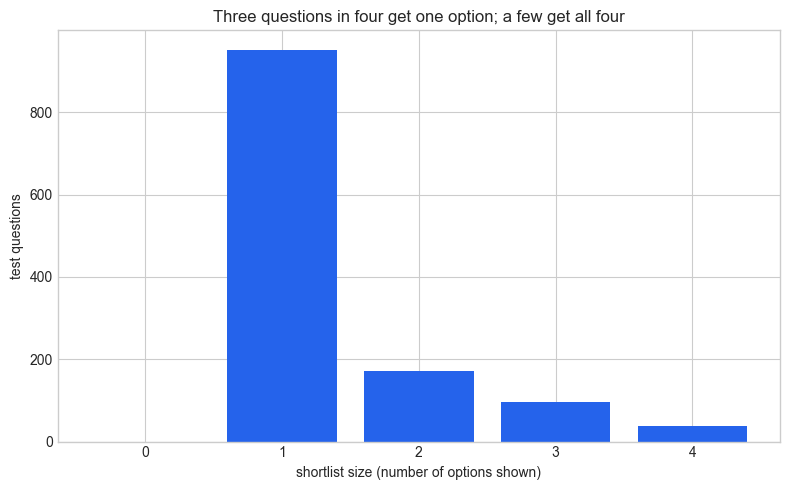

In [4]:
q_hat, sets_lac = lac_sets(probs[cal], truth[cal], probs[test])
cov_lac, size_lac = coverage_and_size(sets_lac, truth[test])
sizes_lac = sets_lac.sum(axis=1)
size_counts = np.bincount(sizes_lac, minlength=5)

print(f"q_hat = {q_hat:.6f}   so an option enters the shortlist when its probability is >= {1 - q_hat:.6f}")
print(f"coverage on {len(test):,} test questions: {cov_lac:.3f}   (target {1 - ALPHA:.2f})")
print(f"mean set size: {size_lac:.2f} options")
print("set sizes:", {s: int(c) for s, c in enumerate(size_counts)})
for s in range(1, 5):
    m = sizes_lac == s
    print(f"   sets of size {s}: {int(m.sum()):4d} questions, the top option is right on {top_correct[test][m].mean():.3f}")

# one test question per set size: in a seeded random order, the first with a short stem
# from a subject not shown yet (the file is sorted by subject, so file order would show
# four abstract algebra questions)
print()
example_order = np.random.default_rng(RANDOM_SEED).permutation(len(test))
shown_subjects = set()
for s in range(1, 5):
    j = next(j for j in example_order if sizes_lac[j] == s
             and len(mmlu["question"].iloc[test[j]]) <= 150
             and mmlu["subject"].iloc[test[j]] not in shown_subjects)
    row = mmlu.iloc[test[j]]
    shown_subjects.add(row["subject"])
    shortlist = [L for k, L in enumerate(LETTERS) if sets_lac[j, k]]
    print(f"size {s} | {row['subject']} | answer key {row['answer']} | shortlist {shortlist}")
    print("    " + textwrap.shorten(row["question"], 100))
    for k, L in enumerate(LETTERS):
        print(f"    {L}  p = {probs[test[j], k]:.6f}   {textwrap.shorten(str(row[L]), 45)}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(range(5), size_counts, color=BLUE)
ax.set_xticks(range(5))
ax.set_xlabel("shortlist size (number of options shown)")
ax.set_ylabel("test questions")
ax.set_title("Three questions in four get one option; a few get all four")
plt.tight_layout()
plt.show()

The corrected quantile is `q_hat = 0.998975`, so the bar is 0.001025: an option enters the shortlist when the model gives it at least that, about one chance in a thousand. Coverage on the 1,257 test questions is 0.889 against the 0.90 target. With 1,257 questions the test noise alone is about $\pm 2\sqrt{0.9 \times 0.1 / 1257} \approx \pm 0.017$, so 0.889 is inside it, and the lottery below shows where this split sits among many. The mean set size is 1.38 options: 951 questions get a single option, 172 get two, 97 get three and 37 get all four.

The size is a difficulty meter, as it was for the triage teams. Where the shortlist has one option the top option is right on 0.898 of questions; on two-option and three-option shortlists it is right on 0.477 and 0.474; on four-option shortlists on 0.324, barely above a guess among four. A long shortlist is the system telling the student that this question is one the model finds hard (field guide §7). The four examples show the mechanics. The sociology question gets one option, because the model puts 1.000000 on it and nothing on the others. The elementary mathematics question is the instructive one: the model puts 0.995930 on D, which is wrong ($-7(8-6) = -14$, option A), and the shortlist rescues the student only because A, at 0.004070, clears the bar. The chemistry question keeps B and C at 0.059 and 0.017 next to the right answer D at 0.924, and the college mathematics question, where the model spreads its belief and the answer key's option gets only 0.033, gets all four. Probabilities like 0.004 are numbers a product team would round to zero on a screen; the shortlist cannot afford to.

No shortlist is empty, and none can be: the top option of four always carries at least 0.25, far above a bar of 0.001. Notebook 04's 1/K rule says empties need a bar above $1/K = 0.25$, that is `q_hat` below 0.75, and the alpha sweep below shows when that happens. The striking number is the bar itself, so we look at where it comes from.

calibration questions where the top option is wrong: 247 of 1256 (19.7%)
   median probability on the (wrong) top option:      0.989
   share with the wrong top option at >= 0.9:          72.9%
   median probability on the answer-key option:       0.001025
   answer-key option recorded as exactly 0:            25.5%
a correct top option has probability >= 0.25, so only wrong answers can be missed;
q_hat is the calibration score at rank 1133 of 1256 (smallest first), so at most 123 misses are allowed
and the shortlist must reach 124 of the 247 wrong answers
bar for inclusion 1 - q_hat = 0.001025


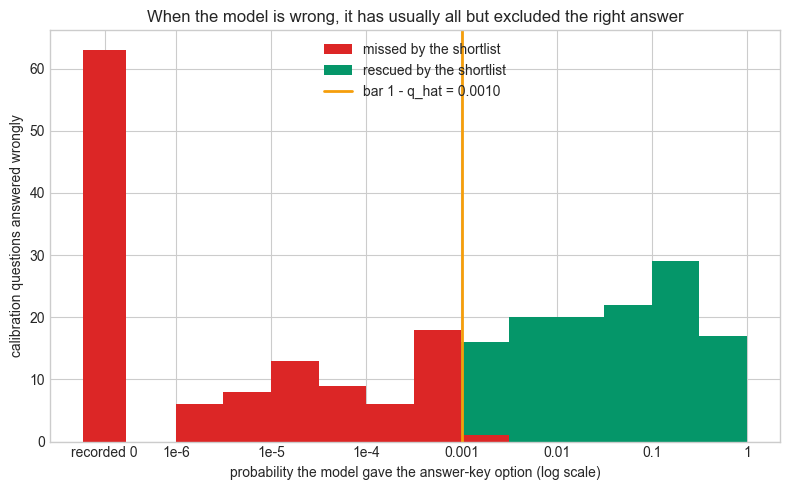

In [5]:
cal_p_true = probs[cal, truth[cal]]
cal_wrong = ~top_correct[cal]
n_cal = len(cal)
# with distinct scores the corrected quantile is the r-th smallest calibration score (the series'
# idiom lands one rank above ceil((n+1)(1-alpha)), notebook 03 section 3), so at most n - r misses
r_qhat = math.ceil(math.ceil((n_cal + 1) * (1 - ALPHA)) / n_cal * (n_cal - 1)) + 1
misses_allowed = n_cal - r_qhat

print(f"calibration questions where the top option is wrong: {cal_wrong.sum()} of {n_cal} ({cal_wrong.mean():.1%})")
print(f"   median probability on the (wrong) top option:      {np.median(p_top[cal][cal_wrong]):.3f}")
print(f"   share with the wrong top option at >= 0.9:          {np.mean(p_top[cal][cal_wrong] >= 0.9):.1%}")
print(f"   median probability on the answer-key option:       {np.median(cal_p_true[cal_wrong]):.6f}")
print(f"   answer-key option recorded as exactly 0:            {np.mean(cal_p_true[cal_wrong] == 0):.1%}")
print(f"a correct top option has probability >= 0.25, so only wrong answers can be missed;")
print(f"q_hat is the calibration score at rank {r_qhat} of {n_cal} (smallest first), so at most {misses_allowed} misses are allowed")
print(f"and the shortlist must reach {cal_wrong.sum() - misses_allowed} of the {cal_wrong.sum()} wrong answers")
print(f"bar for inclusion 1 - q_hat = {1 - q_hat:.6f}")

# histogram of the answer-key probability on wrong answers, log scale; zeros get their own column
wrong_p = cal_p_true[cal_wrong]
log_p = np.log10(wrong_p[wrong_p > 0])
bar_log = np.log10(1 - q_hat)
bins = np.arange(-6.0, 0.01, 0.5)
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist([log_p[log_p < bar_log], log_p[log_p >= bar_log]], bins=bins, stacked=True,
        color=[RED, GREEN], label=["missed by the shortlist", "rescued by the shortlist"])
ax.bar(-6.75, np.sum(wrong_p == 0), width=0.45, color=RED)
ax.axvline(bar_log, color=AMBER, lw=2, label=f"bar 1 - q_hat = {1 - q_hat:.4f}")
ax.set_xticks([-6.75, -6, -5, -4, -3, -2, -1, 0])
ax.set_xticklabels(["recorded 0", "1e-6", "1e-5", "1e-4", "0.001", "0.01", "0.1", "1"])
ax.set_xlabel("probability the model gave the answer-key option (log scale)")
ax.set_ylabel("calibration questions answered wrongly")
ax.set_title("When the model is wrong, it has usually all but excluded the right answer")
ax.legend(loc="upper center")
plt.tight_layout()
plt.show()

This is what `q_hat` = 0.999, a bar of 0.001, means. The model's top option is wrong on 247 of the 1,256 calibration questions (19.7%), and it is wrong with conviction: the median probability on the wrong top option is 0.989, and 72.9% of the wrong answers came with at least 0.9 on the wrong option. The answer-key option on those questions gets a median of 0.001025, and on 25.5% of them it is recorded as exactly zero.

The arithmetic of the bar follows. A correct top option always has probability at least 0.25, so it clears any bar up to 0.25 (any `q_hat` of at least 0.75), this one included, and is never missed; every miss is a wrong answer. The corrected quantile lands on the 1,133rd smallest of the 1,256 scores, so at most 123 calibration questions may be missed, and the shortlist must reach the answer-key option on the other 124 of the 247 wrong answers: almost exactly half. The bar therefore lands at the median probability of the answer-key option among wrong answers, and both numbers read 0.001025. The histogram shows it: the green part is the half of the mistakes the shortlist rescues, the red part (including the column at "recorded 0") the half it does not need to reach, and could only reach by lowering the bar for every question.

So the bar is not a quirk of the code. A model that is confidently wrong one time in five can only be covered 90% of the time by reaching deep into options it all but excluded. A better-calibrated model, one that put a few percent on the right answer when it was wrong, would earn a bar of a few percent and the same coverage; the bar is where the model's quality shows up, never in the coverage (field guide §5).

The obvious product reactions to a bar of 0.001 are to show a fixed number of options, or to hide options the model rates below some cosmetic floor such as 1%. Both are easy to ship, and both are worth measuring before anyone argues for them. We score them on the same test half, next to the LAC shortlist.

In [6]:
rank_test = np.argsort(np.argsort(-probs[test], axis=1, kind="stable"), axis=1, kind="stable")  # 0 = top option
# The stable argsort breaks ties by letter order, and ties are common among options recorded
# at probability 0, so some top-two and top-three "hits" are an accident of the letter. Count
# them, and compute the top-two coverage to expect if those ties were broken at random instead.
p_key = probs[test][np.arange(len(test)), truth[test]]
for k in (2, 3):
    hits = (rank_test < k)[np.arange(len(test)), truth[test]]
    print(f"top-{k} hits where the answer key has probability 0: {int(np.sum(hits & (p_key == 0)))}")
above = (probs[test] > p_key[:, None]).sum(axis=1)      # options strictly more probable than the key
tied = (probs[test] == p_key[:, None]).sum(axis=1)      # options tied with the key, the key included
print(f"top-two coverage with ties broken at random (expected): {np.mean(np.clip(2 - above, 0, tied) / tied):.3f}")
alternatives = {
    "top option only": rank_test < 1,
    "always the top two": rank_test < 2,
    "always the top three": rank_test < 3,
    "hide options below 1%": probs[test] >= 0.01,
    "hide options below 5%": probs[test] >= 0.05,
    f"LAC, bar {1 - q_hat:.4f} (calibrated)": sets_lac,
}
rows = []
for name, sets in alternatives.items():
    cov, size = coverage_and_size(sets, truth[test])
    rows.append((name, cov, size))
fixed_rules = pd.DataFrame(rows, columns=["shortlist rule", "coverage", "mean set size"])
fixed_rules.round(3)

top-2 hits where the answer key has probability 0: 18
top-3 hits where the answer key has probability 0: 39
top-two coverage with ties broken at random (expected): 0.895


,shortlist rule,coverage,mean set size
0,top option only,0.791,1.000
1,always the top two,0.897,2.000
2,always the top three,0.953,3.000
3,hide options below 1%,0.867,1.269
4,hide options below 5%,0.840,1.168
5,"LAC, bar 0.0010 (calibrated)",0.889,1.379


The top option alone covers 0.791, its accuracy on the test half. Always showing the top two covers 0.897, about the target, but it shows two options to every student, including on the 63.8% of questions (section 1) where the model's top option is recorded at probability 1.0; the calibrated shortlist gets 0.889 with 1.38 options. Always showing three covers 0.953 at three options each. The cosmetic floors do what floors do: hiding options below 1% cuts the mean size from 1.38 to 1.27 and coverage from 0.889 to 0.867, and a 5% floor drops it to 0.840. Neither floor comes with a promise of any kind, and nor does the top-two rule: its 0.897 is a fact about this model on this benchmark, measured after the fact, and nothing guarantees it on the next model version.

One caution about the top-two row. It looks competitive here only because 90% happens to sit near this model's top-two accuracy, and it is flattered a little by the letters: the sort breaks ties by letter order, so 18 of its hits (39 for the top three) land on an answer key the model gave probability 0. With those ties broken at random, the top two would be expected to cover 0.895. Ask for 92% and the top-two rule has no answer short of three options for everyone; the calibrated recipe moves its bar and, in the sweep below, gets there with 1.50 options.

The 0.889 above is one calibration draw. Notebook 03 called the realized coverage of a single calibration set a lottery ticket (field guide §4), so before reading anything into the 0.889 we redraw the split 1,000 times and watch coverage, mean set size and the bar move. This is a measurement of the lottery, not a better procedure: the shortlist Quill ships uses one split, and averaging sets over many splits is a documented dead end (field guide §8).

coverage        mean 0.9011   5th-95th percentile [0.8807, 0.9204]
mean set size   mean 1.3726   5th-95th percentile [1.3206, 1.4240]
bar 1 - q_hat   mean 0.0008   5th-95th percentile [0.0002, 0.0016]
splits with coverage below 0.90: 47.9%
splits with coverage below our seeded split's 0.889: 16.7%


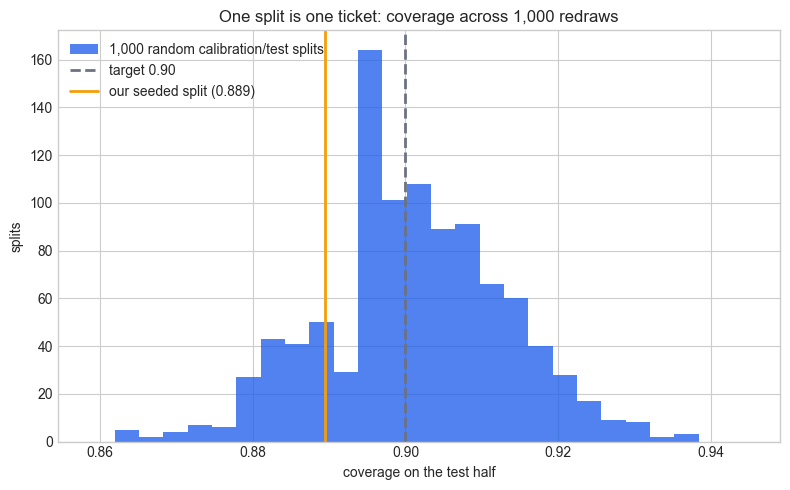

In [7]:
lottery_rng = np.random.default_rng(RANDOM_SEED + 1)
lottery = []
for _ in range(1000):
    p = lottery_rng.permutation(len(truth))
    c, t = p[: len(truth) // 2], p[len(truth) // 2 :]
    qh, sets = lac_sets(probs[c], truth[c], probs[t])
    lottery.append((*coverage_and_size(sets, truth[t]), 1 - qh))
lottery = pd.DataFrame(lottery, columns=["coverage", "mean set size", "bar 1 - q_hat"])

for col in lottery.columns:
    lo, hi = lottery[col].quantile([0.05, 0.95])
    print(f"{col:15s} mean {lottery[col].mean():.4f}   5th-95th percentile [{lo:.4f}, {hi:.4f}]")
print(f"splits with coverage below 0.90: {np.mean(lottery['coverage'] < 0.90):.1%}")
print(f"splits with coverage below our seeded split's {cov_lac:.3f}: {np.mean(lottery['coverage'] < cov_lac):.1%}")

fig, ax = plt.subplots(figsize=(8, 5))
# coverage on 1,257 test questions moves in steps of 1/1257: bins of 4 steps avoid a comb pattern
edges = (np.arange(1080, 1190, 4) - 0.5) / (len(truth) - len(truth) // 2)
ax.hist(lottery["coverage"], bins=edges, color=BLUE, alpha=0.8, label="1,000 random calibration/test splits")
ax.axvline(1 - ALPHA, color=GRAY, ls="--", lw=2, label="target 0.90")
ax.axvline(cov_lac, color=AMBER, lw=2, label=f"our seeded split ({cov_lac:.3f})")
ax.set_xlabel("coverage on the test half")
ax.set_ylabel("splits")
ax.set_title("One split is one ticket: coverage across 1,000 redraws")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

Across 1,000 redraws the mean coverage is 0.901, and the middle 90% of splits run from 0.881 to 0.920, close to the spread notebook 03 measured for a thousand calibration points and a little wider, because our test half is finite too (field guide §4); 47.9% of splits land below 0.90 and the rest above, as a lottery centred on the target should. Only 16.7% of splits come out below our seeded split's 0.889: a somewhat unlucky ticket, not a broken promise. The guarantee is an average over calibration draws and test questions together, and this histogram is what that average looks like one draw at a time.

The picture of section 2 does not depend on the draw. The mean set size stays between 1.32 and 1.42 options in the middle 90% of splits, and the bar between 0.0002 and 0.0016: on every typical split, options the model rates at a tenth of a percent or less have to enter the shortlist. If you quote a coverage number from one split, quote it with that spread.

The product lead will ask the natural next question: what if we promise 95%, or settle for 80%? Changing alpha changes the contract, so it must be decided before calibration and not tuned until the sets look pretty (notebook 04). Here we sweep it only to see how the bar, coverage and the mean set size respond on these probabilities.

calibration questions whose answer-key option is recorded as exactly 0: 5.0%
at alpha = 0.20 the bar is 0.484 > 1/4, so empty sets become possible: 8 of 1,257


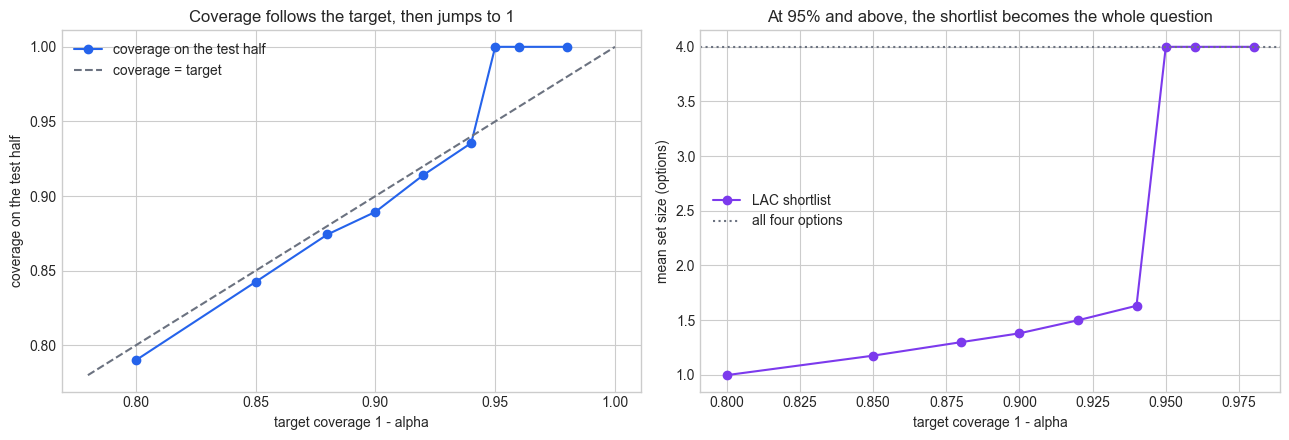

,alpha,target,bar 1 - q_hat,coverage,mean set size
0,0.02,0.98,0.000000,1.000,4.00
1,0.04,0.96,0.000000,1.000,4.00
2,0.05,0.95,0.000000,1.000,4.00
3,0.06,0.94,0.000005,0.936,1.63
4,0.08,0.92,0.000096,0.914,1.50
5,0.10,0.90,0.001025,0.889,1.38
6,0.12,0.88,0.005218,0.874,1.30
7,0.15,0.85,0.047426,0.842,1.18
8,0.20,0.80,0.484480,0.790,1.00


In [8]:
alphas = [0.02, 0.04, 0.05, 0.06, 0.08, 0.10, 0.12, 0.15, 0.20]
rows = []
for a in alphas:
    qh, sets = lac_sets(probs[cal], truth[cal], probs[test], alpha=a)
    rows.append((a, 1 - a, 1 - qh, *coverage_and_size(sets, truth[test])))
sweep = pd.DataFrame(rows, columns=["alpha", "target", "bar 1 - q_hat", "coverage", "mean set size"])

print(f"calibration questions whose answer-key option is recorded as exactly 0: {np.mean(cal_p_true == 0):.1%}")
qh20, sets20 = lac_sets(probs[cal], truth[cal], probs[test], alpha=0.20)
print(f"at alpha = 0.20 the bar is {1 - qh20:.3f} > 1/4, so empty sets become possible: "
      f"{int((sets20.sum(axis=1) == 0).sum())} of {len(test):,}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(sweep["target"], sweep["coverage"], "o-", color=BLUE, label="coverage on the test half")
axes[0].plot([0.78, 1.0], [0.78, 1.0], color=GRAY, ls="--", label="coverage = target")
axes[0].set_xlabel("target coverage 1 - alpha")
axes[0].set_ylabel("coverage on the test half")
axes[0].set_title("Coverage follows the target, then jumps to 1")
axes[0].legend(loc="upper left")
axes[1].plot(sweep["target"], sweep["mean set size"], "o-", color=PURPLE, label="LAC shortlist")
axes[1].axhline(4, color=GRAY, ls=":", label="all four options")
axes[1].set_xlabel("target coverage 1 - alpha")
axes[1].set_ylabel("mean set size (options)")
axes[1].set_title("At 95% and above, the shortlist becomes the whole question")
axes[1].legend(loc="center left")
plt.tight_layout()
plt.show()

sweep.round({"bar 1 - q_hat": 6, "coverage": 3, "mean set size": 2})

Between 80% and 94% coverage follows the target closely, and the mean set size grows smoothly: 1.00 option at 80%, 1.18 at 85%, 1.30 at 88%, 1.38 at 90%, 1.50 at 92% and 1.63 at 94%, where the bar is already down to 0.000005. Then the curve breaks. At 95% and above the bar is exactly zero, every option clears it, and every question gets all four options, with coverage 1.000. The reason is the resolution floor from section 1: 5.0% of calibration questions have their answer-key option recorded as exactly 0, and any target that cannot afford to miss them all forces a bar of zero. The jump is not in the model, it is in the file: a probability below one in a million, or outside the API's top 20 tokens, is indistinguishable from zero, and conformal prediction cannot rank what the score cannot resolve. If Quill ever needs 95%, it needs a score with finer resolution, not a different alpha.

At the other end, at 80% the bar is 0.484, above $1/K = 0.25$, and the first empty shortlists appear: 8 of the 1,257. That is notebook 04's 1/K rule at work. With 1 - alpha near the model's own accuracy of about 0.80, the shortlist shrinks to roughly the model's single answer, and a question whose top option is below the bar gets no option at all. We stay at 90% for the rest of the notebook.

## 3. APS sets

LAC asks of each option separately whether it is plausible enough. APS, from notebook 04 section 8, asks how much probability mass must be stacked, most likely option first, before the answer-key option is included; the score is that cumulative mass. We run notebook 04's version exactly: no randomization, and the top option always kept so that no shortlist is empty. Notebook 04 warned that this version runs conservative. Here we can measure by how much.

In [9]:
def aps_sets(cal_probs, cal_truth, test_probs, alpha=ALPHA, rng=None):
    """APS prediction sets (notebook 04 section 8).

    rng=None: notebook 04's deterministic version. Score = probability mass stacked from the
    most likely option down to, and including, the answer-key option; at test time keep every
    option whose stacked mass is at most q_hat, and always keep the top option.
    rng given: the randomized APS of Romano, Sesia and Candes (2020). The answer-key option
    contributes only a uniform fraction U of its own probability, so the score is the mass
    strictly above it plus U times its probability; one U per question, nothing forced in.
    """
    def stacked(p):
        order = np.argsort(-p, axis=1, kind="stable")          # options, most probable first
        sorted_p = np.take_along_axis(p, order, axis=1)
        return order, sorted_p, sorted_p.cumsum(axis=1)

    order_c, sorted_c, cum_c = stacked(cal_probs)
    rank_true = (order_c == cal_truth[:, None]).argmax(axis=1)
    rows = np.arange(len(cal_truth))
    if rng is None:
        cal_scores = cum_c[rows, rank_true]
    else:
        u = rng.uniform(size=len(cal_truth))
        cal_scores = cum_c[rows, rank_true] - sorted_c[rows, rank_true] * (1 - u)
    q_hat = corrected_quantile(cal_scores, alpha)

    order_t, sorted_t, cum_t = stacked(test_probs)
    if rng is None:
        keep = cum_t <= q_hat
        keep[:, 0] = True                                        # the top option always stays
    else:
        u = rng.uniform(size=len(test_probs))[:, None]
        keep = (cum_t - sorted_t * (1 - u)) <= q_hat
    sets = np.zeros_like(keep)
    np.put_along_axis(sets, order_t, keep, axis=1)               # back to the A-D order
    return q_hat, sets, cal_scores


q_aps, sets_aps, aps_cal_scores = aps_sets(probs[cal], truth[cal], probs[test])
cov_aps, size_aps = coverage_and_size(sets_aps, truth[test])
print(f"APS q_hat = {q_aps!r}")
print(f"calibration APS scores within 0.000001 of 1: {np.mean(aps_cal_scores >= 1 - 1e-6):.1%}")
print(f"APS (deterministic): coverage {cov_aps:.3f}, mean set size {size_aps:.2f}, "
      f"sizes {dict(enumerate(np.bincount(sets_aps.sum(axis=1), minlength=5).tolist()))}")
print(f"LAC:                 coverage {cov_lac:.3f}, mean set size {size_lac:.2f}, "
      f"sizes {dict(enumerate(size_counts.tolist()))}")

# where do the shorter APS sets come from? Sum each row's probabilities in the order aps_sets
# stacks them: six-decimal rounding can leave the total a hair above 1.0 = q_hat
order_test = np.argsort(-probs[test], axis=1, kind="stable")
total_mass = np.take_along_axis(probs[test], order_test, axis=1).cumsum(axis=1)[:, -1]
over_one = total_mass > 1.0
short_aps = sets_aps.sum(axis=1) < 4
missed_aps = ~sets_aps[np.arange(len(test)), truth[test]]
print(f"test questions whose stacked probabilities total more than 1.0: {over_one.sum()} "
      f"(by at most {(total_mass - 1).max():.6f})")
print(f"   sets shorter than four: {short_aps.sum()}, all among them: {bool(np.all(over_one[short_aps]))}; "
      f"misses: {missed_aps.sum()}, all among them: {bool(np.all(over_one[missed_aps]))}")

APS q_hat = 1.0
calibration APS scores within 0.000001 of 1: 75.6%
APS (deterministic): coverage 0.990, mean set size 3.94, sizes {0: 0, 1: 0, 2: 14, 3: 43, 4: 1200}
LAC:                 coverage 0.889, mean set size 1.38, sizes {0: 0, 1: 951, 2: 172, 3: 97, 4: 37}
test questions whose stacked probabilities total more than 1.0: 57 (by at most 0.000001)
   sets shorter than four: 57, all among them: True; misses: 13, all among them: True


The deterministic APS covers 0.990 of test questions with a mean of 3.94 options: 1,200 of the 1,257 questions get all four. Even the exceptions are artefacts. The 57 shorter sets are exactly the 57 questions whose six-decimal probabilities, stacked in order, add up to a hair more than 1 (by at most 0.000001), so the last option or two stack past `q_hat` = 1.0 and drop out; all 13 misses are among them. Up to rounding, the deterministic APS shows all four options on every question, and its coverage is 1. It keeps the promise and is useless, which is field guide §5 in one line.

The overshoot has a precise address, and it is not the one notebook 04 found. There, the forced top option did the damage. Here, the damage is done by a tie at the ceiling of the score. When the model gives the answer-key option probability 1.0, the stacked mass up to and including it is 1.0, exactly the score of a question whose answer-key option was ranked last. Because the model is so often certain, 75.6% of calibration scores sit within one millionth of 1, the 90% quantile lands inside that block, and `q_hat` is exactly 1.0. At test time a question with a top option at 1.0 has stacked mass 1.0 at every position, since the remaining options add zeros, so every option's stacked mass is at most `q_hat` and all four are kept. On peaked probabilities the deterministic APS score cannot tell "confidently right" from "deeply wrong", and the set inherits that blindness.

The textbook APS (Romano, Sesia and Candes 2020) is randomized for exactly this reason: the answer-key option contributes only a uniform random fraction of its own probability to the score, which spreads the block of scores at 1.0 across the whole range. We run it, and then run it again with a second random draw, to see what randomization costs a product that shows sets to students.

In [10]:
q_raps, sets_raps, _ = aps_sets(probs[cal], truth[cal], probs[test], rng=np.random.default_rng(RANDOM_SEED))
cov_raps, size_raps = coverage_and_size(sets_raps, truth[test])
_, sets_raps_2, _ = aps_sets(probs[cal], truth[cal], probs[test], rng=np.random.default_rng(RANDOM_SEED + 1))
changed = np.mean((sets_raps != sets_raps_2).any(axis=1))

print(f"randomized APS: q_hat = {q_raps:.6f}, coverage {cov_raps:.3f}, mean set size {size_raps:.2f}, "
      f"sizes {dict(enumerate(np.bincount(sets_raps.sum(axis=1), minlength=5).tolist()))}")
print(f"LAC:            q_hat = {q_hat:.6f}, coverage {cov_lac:.3f}, mean set size {size_lac:.2f}")
print(f"test questions whose shortlist changes under a second random draw: {changed:.1%}")
print(f"test questions in the same shortlist under LAC and randomized APS: "
      f"{np.mean((sets_lac == sets_raps).all(axis=1)):.1%}")

randomized APS: q_hat = 0.999455, coverage 0.888, mean set size 1.37, sizes {0: 1, 1: 954, 2: 173, 3: 92, 4: 37}
LAC:            q_hat = 0.998975, coverage 0.889, mean set size 1.38
test questions whose shortlist changes under a second random draw: 4.7%
test questions in the same shortlist under LAC and randomized APS: 97.1%


Randomized, APS covers 0.888 with 1.37 options, within a hair of LAC's 0.889 and 1.38, and 97.1% of test questions get the very same shortlist from both. That is no coincidence. On a wrong answer whose answer-key option has probability 0.001, the mass stacked above it is about 0.999, so both scores are about 0.999 and both methods rank the hard questions the same way. Where the probabilities are this peaked there is little room for APS's adaptivity to differ from LAC.

The price of the randomization is printed in the third line: under a second random draw, 4.7% of test questions get a different shortlist. Two students asking the same question on the same day could see different options, and the difference is a coin flip, not evidence. One test question even got an empty set, which randomized APS allows. For a product that shows shortlists to people, LAC delivers the same coverage and the same sizes here without the coin, so it is the method we carry forward. The APS lesson to keep is the general one: before trusting any score, look for large blocks of tied scores near `q_hat`, because a tie at `q_hat` forces the set to take or leave the whole block.

## 4. When the API gives no probabilities

Not every hosted model returns log-probabilities. When this course's data was generated, a GPT-5-family reasoning deployment on the same Azure account returned the log-probability of its chosen token only, with no alternatives, so it could not have scored the other options (`llm_data/README.md`, "Why this model"); a vendor can also change what an API exposes in a new version. The fallback from notebook 16 is self-consistency: ask the same question ten times at temperature 1.0 and count how often each letter comes back. The score is then notebook 04's LAC score on agreement frequencies, one minus the share of the ten samples that chose the answer-key option. Of the 25,130 samples, 85 were not a letter (spread over 19 questions; on three questions all ten samples were something else); those samples count for no option, so a question's four counts can add up to less than ten. Stated confidence, the third source from notebook 16, is not a candidate here: the model states one number for the option it chose and nothing about the other three, so it cannot rank options within a question.

samples that were not a letter: 85 of 25130 | questions affected: 19 | questions with no letter at all: 3
calibration questions by how many of 10 samples chose the answer-key option:
   {0: 180, 1: 24, 2: 16, 3: 8, 4: 6, 5: 14, 6: 13, 7: 18, 8: 18, 9: 19, 10: 940}
q_hat = 1.000   calibration scores tied at q_hat: 180 of 1256
agreement LAC, no tie-breaking: coverage 1.000, mean set size 4.00


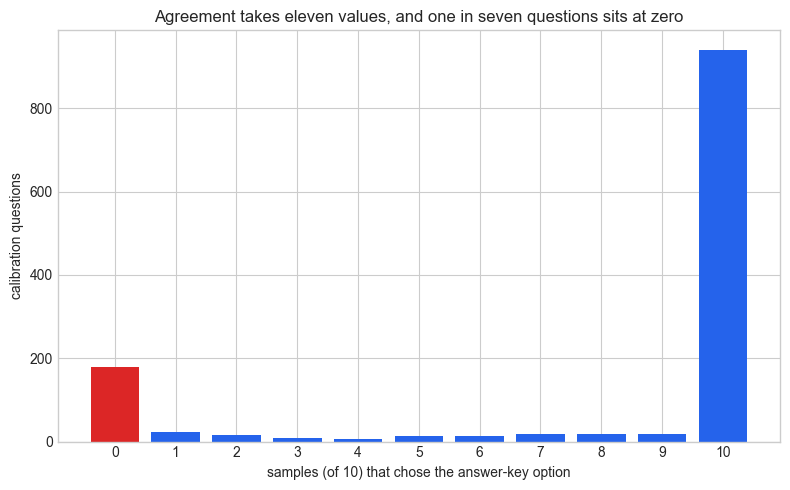

In [11]:
freq = counts / 10.0                                     # share of the 10 samples choosing each option
cal_true_count = counts[cal, truth[cal]].astype(int)
print("samples that were not a letter:", int(mmlu["samples_invalid"].sum()), "of", 10 * len(mmlu),
      "| questions affected:", int((mmlu["samples_invalid"] > 0).sum()),
      "| questions with no letter at all:", int((mmlu["samples_invalid"] == 10).sum()))
print("calibration questions by how many of 10 samples chose the answer-key option:")
print("  ", dict(enumerate(np.bincount(cal_true_count, minlength=11).tolist())))

q_agree, sets_agree = lac_sets(freq[cal], truth[cal], freq[test])
cov_agree, size_agree = coverage_and_size(sets_agree, truth[test])
agree_scores = 1.0 - freq[cal, truth[cal]]
print(f"q_hat = {q_agree:.3f}   calibration scores tied at q_hat: {np.sum(agree_scores == q_agree)} of {len(cal)}")
print(f"agreement LAC, no tie-breaking: coverage {cov_agree:.3f}, mean set size {size_agree:.2f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(range(11), np.bincount(cal_true_count, minlength=11), color=[RED] + [BLUE] * 10)
ax.set_xticks(range(11))
ax.set_xlabel("samples (of 10) that chose the answer-key option")
ax.set_ylabel("calibration questions")
ax.set_title("Agreement takes eleven values, and one in seven questions sits at zero")
plt.tight_layout()
plt.show()

The agreement score has a different shape from the token probability. Out of 1,256 calibration questions, 1,076 have at least one sample on the answer-key option and 940 of those have all ten, while 180 (14.3%, the red bar) have none: on those questions the model never once sampled the right answer. That is the same confident wrongness as in section 2, seen through a coarser instrument. Ten samples cannot see an option the model gives probability 0.001; on average it would take a thousand samples to see it once.

So the recipe hits a wall. A miss rate of at most 10% cannot be reached by leaving out the never-sampled block, because the block alone is 14.3%. The corrected quantile lands inside it, `q_hat` is 1.0 (a bar of zero), 180 calibration scores are tied at `q_hat`, and every option with a count of zero or more, which is every option, joins every shortlist. Coverage is 1.000 with all four options for every question: the promise kept, the product destroyed.

Ties are the reason, and the leaderboard argument says exactly how (notebook 03 section 3, the sandwich). When the scores are all distinct, the newcomer's score is equally likely to land in any of the $n + 1$ positions, so the chance it lands at or below the bar is exactly the bar's rank divided by $n + 1$. In symbols, with $r$ the rank of $\hat{q}$ among the $n$ calibration scores,

$$P(\text{covered}) = \frac{r}{n + 1},$$

which for our $n = 1{,}256$ and the series' idiom ($r = 1{,}133$) is 0.901: at least 90% and not much more. When scores tie, `q_hat` cannot stop in the middle of a tied block. It must take the whole block or leave it, and coverage jumps from below target to whatever the block's top edge allows, here from 0.857 to 1.

The standard repair is a **tie-breaking jitter**: add to every agreement frequency a tiny independent uniform number, here between 0 and 0.001, drawn once per question and option. It is far smaller than the gap of 0.1 between two counts, so it never reorders different counts; it only puts a random order on questions and options that are tied. That makes the scores distinct, so the formula above applies again. The jitter is a tie-breaking device, not new information: whatever it decides inside a tied block, it decides by coin flip. We compare the result with the token-probability shortlist on the seeded split and on 500 redraws of the split and of the jitter.

In [12]:
jitter_rng = np.random.default_rng(RANDOM_SEED)
freq_jit = freq + jitter_rng.uniform(0.0, 0.001, size=freq.shape)
q_jit, sets_jit = lac_sets(freq_jit[cal], truth[cal], freq_jit[test])
cov_jit, size_jit = coverage_and_size(sets_jit, truth[test])
never_sampled = counts[test] == 0
print(f"agreement + jitter: q_hat = {q_jit:.6f} (bar {1 - q_jit:.6f}), coverage {cov_jit:.3f}, mean set size {size_jit:.2f}, "
      f"sizes {dict(enumerate(np.bincount(sets_jit.sum(axis=1), minlength=5).tolist()))}")
print(f"options sampled at least once that join the shortlist: {sets_jit[~never_sampled].mean():.1%}")
print(f"never-sampled options that join the shortlist:        {sets_jit[never_sampled].mean():.1%}")

rep_rng = np.random.default_rng(RANDOM_SEED + 2)
rows = []
for _ in range(500):
    p = rep_rng.permutation(len(truth))
    c, t = p[: len(truth) // 2], p[len(truth) // 2 :]
    fj = freq + rep_rng.uniform(0.0, 0.001, size=freq.shape)
    rows.append((*coverage_and_size(lac_sets(probs[c], truth[c], probs[t])[1], truth[t]),
                 *coverage_and_size(lac_sets(fj[c], truth[c], fj[t])[1], truth[t])))
rep = np.array(rows)
print(f"500 redraws, token probabilities: coverage {rep[:, 0].mean():.3f}, mean set size {rep[:, 1].mean():.2f}")
print(f"500 redraws, agreement + jitter:  coverage {rep[:, 2].mean():.3f}, mean set size {rep[:, 3].mean():.2f}")
print(f"exact coverage with distinct scores, r / (n + 1) = {r_qhat} / {n_cal + 1} = {r_qhat / (n_cal + 1):.3f}")

summary = pd.DataFrame(
    [("LAC, token probability", cov_lac, size_lac, "no"),
     ("APS, deterministic (notebook 04)", cov_aps, size_aps, "no"),
     ("APS, randomized", cov_raps, size_raps, "yes"),
     ("LAC, agreement of 10 samples", cov_agree, size_agree, "no"),
     ("LAC, agreement + jitter", cov_jit, size_jit, "yes")],
    columns=["shortlist", "coverage", "mean set size", "random?"])
summary.round(3)

agreement + jitter: q_hat = 0.999334 (bar 0.000666), coverage 0.894, mean set size 2.14, sizes {0: 0, 1: 300, 2: 544, 3: 344, 4: 69}
options sampled at least once that join the shortlist: 100.0%
never-sampled options that join the shortlist:        34.5%


500 redraws, token probabilities: coverage 0.901, mean set size 1.37
500 redraws, agreement + jitter:  coverage 0.901, mean set size 2.12
exact coverage with distinct scores, r / (n + 1) = 1133 / 1257 = 0.901


,shortlist,coverage,mean set size,random?
0,"LAC, token probability",0.889,1.379,no
1,"APS, deterministic (notebook 04)",0.990,3.944,no
2,"APS, randomized",0.888,1.372,yes
3,"LAC, agreement of 10 samples",1.000,4.000,no
4,"LAC, agreement + jitter",0.894,2.145,yes


With the jitter the agreement shortlist covers 0.894 with a mean of 2.14 options, and the mechanism is visible in the two middle lines: every option sampled at least once joins the shortlist (100.0%), and 34.5% of never-sampled options join it too. The bar landed at 0.000666, inside the jitter's range of 0 to 0.001, so a never-sampled option enters when its random number is above about two thirds of that range, about one time in three. That is how a promise of 90% is kept when 14.3% of answer-key options were never sampled: by showing a randomly chosen third of the never-sampled options. Across 500 redraws both scores average 0.901 coverage, the $r/(n+1) = 0.901$ that distinct scores guarantee, so the two shortlists are compared at the same coverage.

At that same coverage, token probabilities need 1.37 options per question and agreement needs 2.12, about 55% more. The difference is resolution. Among the options nobody sampled, the token probabilities still distinguish 0.001 from 0.000001, so the shortlist can take the plausible ones and leave the rest; ten samples see all of them as zero, and the jitter can only pick among them blindly. If your API returns probabilities, use them; if it does not, agreement with jitter is a valid shortlist that is honest about being coarser, and it costs ten answers per question instead of one.

| Shortlist | What the score asks | What happened on Quill's questions | Pitfall |
|---|---|---|---|
| LAC on token probability | is this option individually plausible enough? | bar 0.001; 0.889 coverage with 1.38 options | rounding small probabilities to zero on screen, or adding a cosmetic floor, quietly gives up coverage |
| APS, deterministic | how much mass must be stacked before the answer is in? | all four options, up to rounding: a confident right answer scores like a buried one | ties at the top of the score push `q_hat` to 1 |
| APS, randomized | the same, with the last option counted fractionally | coverage and sizes within 0.01 of LAC | the same question can get a different shortlist on a second draw |
| LAC on agreement counts | how often did ten samples pick this option? | four options for everyone without tie-breaking | eleven possible values make a tied block at `q_hat` |
| agreement + jitter | the same, with ties put in random order | 0.894 coverage with 2.14 options | the jitter decides which never-sampled options appear; say so |

## 5. Ninety percent overall, not per subject

The 0.90 in every section so far is a marginal number: an average over all subjects mixed together (field guide §3). Nothing in the guarantee promises a student revising moral scenarios what it promises a student revising sociology, and section 1 showed the model's accuracy ranges from 0.52 to 0.92 across subjects. Field guide §9 says to print the per-group table before shipping. With 32 to 52 calibration questions per subject on one split, and the rest of each subject's 86 to 90 questions in the test half, a single split's per-subject table is too noisy to read (about $\pm 0.09$ around 0.90 for 45 test questions), so we average each subject's coverage over 300 redraws of the split, again as a measurement device, not a procedure. The same 300 splits are reused below.

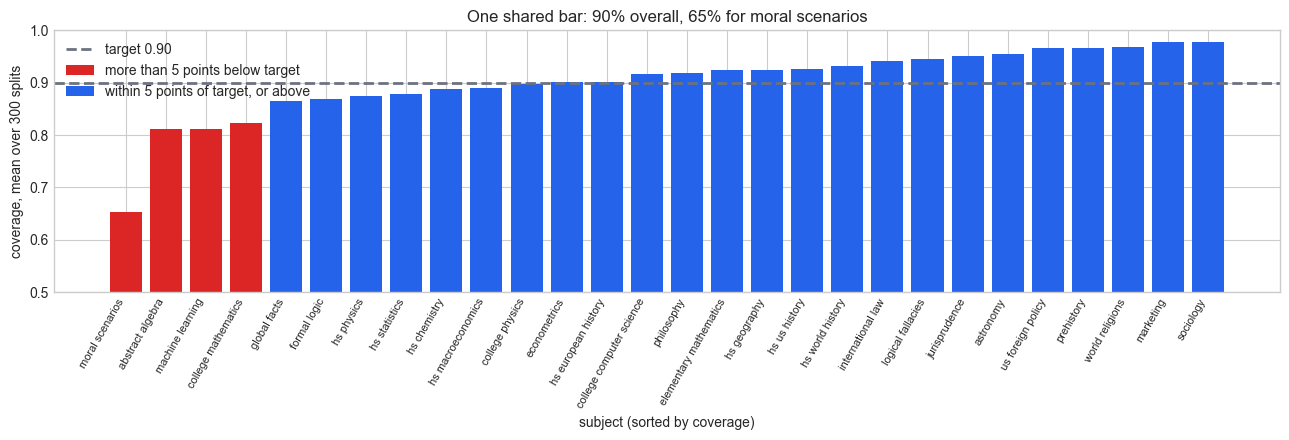

overall coverage, mean over the 300 splits: 0.902
share of all questions whose answer-key option is recorded at p = 0: 0.051
best covered: world_religions 0.968, marketing 0.978, sociology 0.978


,subject,top-option accuracy,answer key at p = 0,coverage (shared bar),size (shared bar)
0,moral_scenarios,0.556,0.233,0.652,1.373
1,abstract_algebra,0.644,0.111,0.812,1.559
2,machine_learning,0.756,0.156,0.812,1.223
3,college_mathematics,0.522,0.044,0.823,2.063
4,global_facts,0.622,0.033,0.866,2.137
5,formal_logic,0.667,0.033,0.868,1.746
6,high_school_physics,0.667,0.067,0.874,1.619
7,high_school_statistics,0.833,0.089,0.877,1.221


In [13]:
SUBJECTS = np.array(sorted(set(subject)))
sid = np.searchsorted(SUBJECTS, subject)                 # subject index of every question
split_rng = np.random.default_rng(RANDOM_SEED + 3)
subject_splits = [split_rng.permutation(len(truth)) for _ in range(300)]


def per_subject(sets, t):
    """Coverage and mean set size within each subject, for test questions t."""
    hit, size = sets[np.arange(len(t)), truth[t]], sets.sum(axis=1)
    return ([hit[sid[t] == k].mean() for k in range(len(SUBJECTS))],
            [size[sid[t] == k].mean() for k in range(len(SUBJECTS))])


shared_cov, shared_size, shared_overall = [], [], []
for p in subject_splits:
    c, t = p[: len(truth) // 2], p[len(truth) // 2 :]
    sets = lac_sets(probs[c], truth[c], probs[t])[1]
    cov_k, size_k = per_subject(sets, t)
    shared_cov.append(cov_k)
    shared_size.append(size_k)
    shared_overall.append(coverage_and_size(sets, truth[t])[0])
by_subject = pd.DataFrame({
    "subject": SUBJECTS,
    "top-option accuracy": [top_correct[sid == k].mean() for k in range(len(SUBJECTS))],
    # share of the subject's questions whose answer-key option is recorded as probability 0
    "answer key at p = 0": [np.mean(probs[sid == k, truth[sid == k]] == 0) for k in range(len(SUBJECTS))],
    "coverage (shared bar)": np.mean(shared_cov, axis=0),
    "size (shared bar)": np.mean(shared_size, axis=0),
}).sort_values("coverage (shared bar)").reset_index(drop=True)

short = by_subject["subject"].str.replace("high_school_", "hs ").str.replace("_", " ")
low = (by_subject["coverage (shared bar)"] < 0.85).to_numpy()
x = np.arange(len(by_subject))
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(x[low], by_subject["coverage (shared bar)"][low], color=RED, label="more than 5 points below target")
ax.bar(x[~low], by_subject["coverage (shared bar)"][~low], color=BLUE, label="within 5 points of target, or above")
ax.axhline(1 - ALPHA, color=GRAY, ls="--", lw=2, label="target 0.90")
ax.set_xticks(range(len(by_subject)))
ax.set_xticklabels(short, rotation=60, ha="right", fontsize=8)
ax.set_ylim(0.5, 1.0)
ax.set_ylabel("coverage, mean over 300 splits")
ax.set_xlabel("subject (sorted by coverage)")
ax.set_title("One shared bar: 90% overall, 65% for moral scenarios")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print(f"overall coverage, mean over the 300 splits: {np.mean(shared_overall):.3f}")
print(f"share of all questions whose answer-key option is recorded at p = 0: {np.mean(probs[np.arange(len(truth)), truth] == 0):.3f}")
print("best covered: " + ", ".join(f"{s} {v:.3f}" for s, v in
                                  zip(by_subject["subject"].tail(3), by_subject["coverage (shared bar)"].tail(3))))
by_subject.round(3).head(8)

The overall coverage, 0.902 on average over the 300 splits, hides a range from 0.652 to 0.978. Four subjects sit more than five points below target: moral scenarios at 0.652, abstract algebra and machine learning at 0.812, and college mathematics at 0.823; the best covered, marketing and sociology, reach 0.978. These are averages over 300 splits, so the calibration lottery is averaged away; what remains is the sampling of each subject's 86 to 90 questions, worth a few points, not twenty-five.

The mechanism is notebook 04's cardiac story. One shared bar is set by the mix of all subjects, and a subject whose wrong answers are more confidently wrong than average falls below it. Accuracy alone does not predict the damage; how wrong the model is when it is wrong does. The column to read is the share of a subject's questions whose answer-key option is recorded at probability exactly zero, out of reach of any bar above zero: 0.233 for moral scenarios, 0.156 for machine learning and 0.111 for abstract algebra, against 0.051 over all questions. Moral scenarios is the extreme: its mean shortlist under the shared bar is 1.37 options, no longer than average, because the model is as sure of its wrong answers there as anywhere else. Machine learning, at 0.756 accuracy, is not among the ten weakest subjects, yet it ties abstract algebra as the second worst covered. College mathematics gets there the other way: it has the lowest accuracy, 0.522, but less extreme mistakes (0.044 at zero), so the shared bar rescues more of them, at the price of the second longest shortlists in the table, 2.06 options (after global facts at 2.14). Moral scenarios also asks for judgments against "ordinary moral standards", where the answer key itself is open to dispute; coverage is always measured against the key, and a debatable key becomes part of the promise.

The repair is notebook 04's Mondrian calibration with subjects as the groups: compute a separate bar from each subject's own calibration questions, and judge each test question against the bar of its subject. Unlike notebook 04, the group is known at test time, since a question's subject is printed on it, so each question simply uses its own subject's bar. The guarantee becomes 90% within each subject, on average over that subject's calibration draw. We measure it on the same 300 splits, together with a variant that breaks the ties at probability zero with the section 4 device: a jitter below the file's resolution, between 0 and 0.0000001.

seeded split: 9 of 28 subjects get q_hat = 1.0 (all four options):
   abstract_algebra, econometrics, global_facts, high_school_chemistry, high_school_geography, high_school_statistics, high_school_world_history, machine_learning, moral_scenarios


shared bar:                 coverage 0.902, mean set size 1.37
one bar per subject:        coverage 0.945, mean set size 2.22
one bar per subject + jitter: coverage 0.933, mean set size 1.81
cov own          per subject, from 0.926 to 1.000
cov own+jit      per subject, from 0.926 to 0.937
own+jit 5th pct  per subject, from 0.818 to 0.860


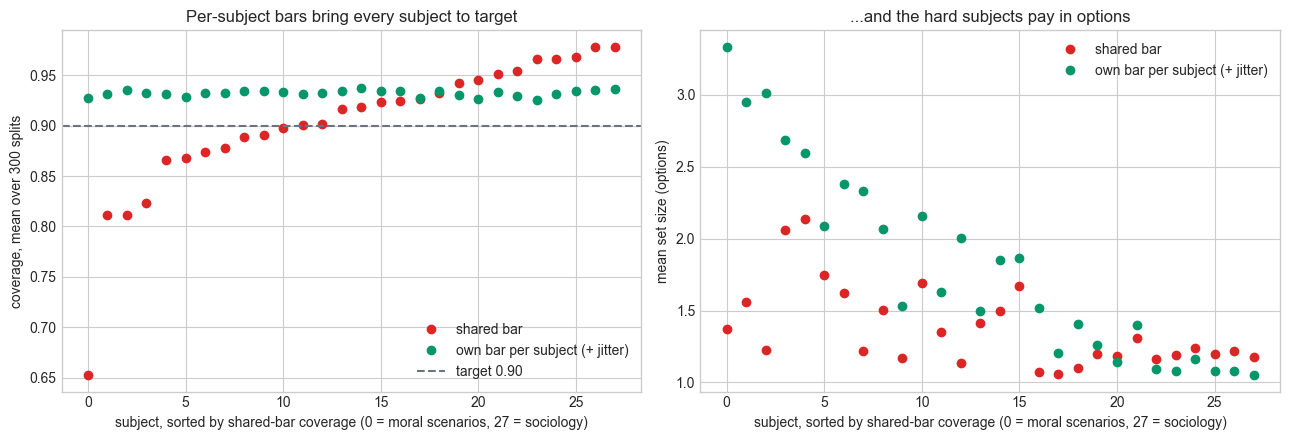

,subject,cov shared,cov own,cov own+jit,own+jit 5th pct,size shared,size own,size own+jit
0,moral_scenarios,0.652,1.000,0.927,0.830,1.373,4.000,3.333
1,abstract_algebra,0.812,0.984,0.932,0.821,1.559,3.834,2.950
2,machine_learning,0.812,0.998,0.936,0.848,1.223,3.983,3.010
3,college_mathematics,0.823,0.936,0.932,0.844,2.063,2.921,2.688
4,global_facts,0.866,0.935,0.932,0.833,2.137,2.724,2.595
5,formal_logic,0.868,0.932,0.929,0.820,1.746,2.197,2.086
6,high_school_physics,0.874,0.951,0.932,0.839,1.619,3.140,2.377
7,high_school_statistics,0.877,0.977,0.932,0.837,1.221,3.595,2.329
8,high_school_chemistry,0.889,0.945,0.935,0.822,1.501,2.758,2.066
9,high_school_macroeconomics,0.891,0.939,0.935,0.830,1.173,2.055,1.532


In [14]:
def mondrian_lac_sets(c, t, p_matrix):
    """LAC with one q_hat (so one bar, 1 - q_hat) per subject, from its own calibration questions."""
    q_hats = np.zeros(len(SUBJECTS))
    for k in range(len(SUBJECTS)):
        ck = c[sid[c] == k]
        q_hats[k] = corrected_quantile(1.0 - p_matrix[ck, truth[ck]], ALPHA)
    return q_hats, (1.0 - p_matrix[t]) <= q_hats[sid[t]][:, None]


q_hats_seeded, _ = mondrian_lac_sets(cal, test, probs)
print(f"seeded split: {np.sum(q_hats_seeded == 1.0)} of {len(SUBJECTS)} subjects get q_hat = 1.0 (all four options):")
print("   " + ", ".join(SUBJECTS[q_hats_seeded == 1.0]))

mondrian_rng = np.random.default_rng(RANDOM_SEED + 4)
own_cov, own_size, jit_cov, jit_size, overall = [], [], [], [], []
for p in subject_splits:
    c, t = p[: len(truth) // 2], p[len(truth) // 2 :]
    _, sets_own = mondrian_lac_sets(c, t, probs)
    probs_jit = probs + mondrian_rng.uniform(0.0, 1e-7, size=probs.shape)
    _, sets_own_jit = mondrian_lac_sets(c, t, probs_jit)
    for sets, cov_list, size_list in [(sets_own, own_cov, own_size), (sets_own_jit, jit_cov, jit_size)]:
        cov_k, size_k = per_subject(sets, t)
        cov_list.append(cov_k)
        size_list.append(size_k)
    overall.append((*coverage_and_size(lac_sets(probs[c], truth[c], probs[t])[1], truth[t]),
                    *coverage_and_size(sets_own, truth[t]), *coverage_and_size(sets_own_jit, truth[t])))
overall = np.mean(overall, axis=0)
print(f"shared bar:                 coverage {overall[0]:.3f}, mean set size {overall[1]:.2f}")
print(f"one bar per subject:        coverage {overall[2]:.3f}, mean set size {overall[3]:.2f}")
print(f"one bar per subject + jitter: coverage {overall[4]:.3f}, mean set size {overall[5]:.2f}")

order = [list(SUBJECTS).index(s) for s in by_subject["subject"]]       # same order as the table above
own = pd.DataFrame({
    "subject": by_subject["subject"],
    "cov shared": by_subject["coverage (shared bar)"],
    "cov own": np.mean(own_cov, axis=0)[order],
    "cov own+jit": np.mean(jit_cov, axis=0)[order],
    "own+jit 5th pct": np.quantile(jit_cov, 0.05, axis=0)[order],
    "size shared": by_subject["size (shared bar)"],
    "size own": np.mean(own_size, axis=0)[order],
    "size own+jit": np.mean(jit_size, axis=0)[order],
})
for col in ["cov own", "cov own+jit", "own+jit 5th pct"]:
    print(f"{col:16s} per subject, from {own[col].min():.3f} to {own[col].max():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(len(own))
axes[0].plot(x, own["cov shared"], "o", color=RED, label="shared bar")
axes[0].plot(x, own["cov own+jit"], "o", color=GREEN, label="own bar per subject (+ jitter)")
axes[0].axhline(1 - ALPHA, color=GRAY, ls="--", label="target 0.90")
axes[0].set_xlabel("subject, sorted by shared-bar coverage (0 = moral scenarios, 27 = sociology)")
axes[0].set_ylabel("coverage, mean over 300 splits")
axes[0].set_title("Per-subject bars bring every subject to target")
axes[0].legend(loc="lower right")
axes[1].plot(x, own["size shared"], "o", color=RED, label="shared bar")
axes[1].plot(x, own["size own+jit"], "o", color=GREEN, label="own bar per subject (+ jitter)")
axes[1].set_xlabel("subject, sorted by shared-bar coverage (0 = moral scenarios, 27 = sociology)")
axes[1].set_ylabel("mean set size (options)")
axes[1].set_title("...and the hard subjects pay in options")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

own.round(3)

With one bar per subject, every subject's average coverage reaches the target: from 0.926 to 1.000 with plain token probabilities, and from 0.926 to 0.937 with the sub-resolution jitter. Moral scenarios moves from 0.652 to 1.000 (plain) or 0.927 (jitter), college mathematics from 0.823 to 0.932 (jitter). The averages run above 0.90 because a calibration seat is worth about two points when a subject has only about 45 calibration questions: the corrected rank rounds up by up to one seat and the series' idiom adds one more, so with distinct scores the exact coverage is about 43/46 = 0.935, which is where the jittered column sits. Overall, coverage rises from 0.902 to 0.945 with plain per-subject bars and 0.933 with the jitter.

The price comes in two currencies. The first is set size. The mean shortlist grows from 1.37 options under the shared bar to 2.22 with plain per-subject bars, and 1.81 with the jitter. The gap between those last two numbers is the resolution floor again. With 32 to 52 calibration questions, a subject's `q_hat` is one of its two to four worst calibration scores (the third worst at 45), so a subject with that many calibration questions whose answer-key option was recorded at exactly zero gets `q_hat` = 1.0, a bar of zero, and four options on every question. On the seeded split that happened to 9 of the 28 subjects, including easy ones such as high school geography and high school world history. Breaking the zero ties at random removes that artefact, and what remains is the honest price: moral scenarios needs 3.33 options on average, machine learning 3.01 and abstract algebra 2.95, while sociology still gets 1.05. A subject on which the model is often confidently wrong cannot be covered with short lists.

The second currency is calibration data, and it is the notebook 03 lottery at the scale of a subject. The 5th-percentile column shows what one split can deliver: with about 45 calibration questions and 45 test questions per subject, one split in twenty leaves a subject between 0.82 and 0.86 even with its own bar, and the mean hides that. This spread mixes the calibration lottery with test noise on 45 questions, but the calibration part alone is the order-statistics spread notebook 03 measured at $n = 50$ (5th to 95th percentile 0.828 to 0.958). Notebook 03's rule of thumb, about a thousand calibration points to keep a 90% promise within 0.88 to 0.92, would here mean about 1,000 labelled questions per subject, 28,000 in all, for the per-subject promise to be as tight as the overall one is today.

Two choices remain for the product lead, and both are product decisions, not statistical ones: which groups need their own promise (subjects here; for Quill perhaps also grade levels or languages, each a separate table), and how many labelled questions per group Quill can afford. And one caution belongs next to every number in this notebook: MMLU is a public benchmark that may have been in the model's training data (contamination, notebook 16). These coverages transfer to questions exchangeable with these ones, not automatically to the questions Quill's students type; calibrate on a labelled sample of Quill's own traffic before quoting the promise to them (field guide §26).

## 6. Common mistakes to avoid

1. **"Fixing" a tiny bar.** A bar of 0.001 is the model's confident wrongness, measured. Hiding options below 1% cut coverage from 0.889 to 0.867 here, and a fixed top-two rule reached the target only because 90% happened to sit near this model's top-two accuracy. Change the model or the score if the sets are too long; do not edit the sets (field guide §7).
2. **Running a deterministic score into a block of ties.** Notebook 04's APS gave all four options on every question, up to rounding, on these probabilities, and agreement counts without tie-breaking gave four options to everyone. Before trusting any score, count the calibration scores tied at the bar; if there is a block, break ties with a jitter and say so, or use a score with finer resolution (field guide §5 and §12).
3. **Asking for more than the score can resolve.** Every target of 95% or more forced a bar of zero and four options everywhere, because 5.0% of answer-key options were recorded as probability zero. Check the share of zero-probability answers before you promise a level.
4. **Quoting one split's coverage as the coverage.** Our seeded split read 0.889; the lottery over 1,000 splits ran from 0.881 to 0.920 around 0.901. Quote the spread, and do not average sets over splits to smooth it (field guide §4 and §8).
5. **Promising 90% per subject from a 90% overall result.** Moral scenarios was covered 65% of the time under the shared bar. If a group matters on its own, give it its own bar and budget for the calibration questions it needs (field guide §3 and §9).
6. **Calibrating on a benchmark and quoting the promise for users, or changing the prompt afterwards.** The bar belongs to one procedure and one population of questions; a new prompt, model version or option order needs a new calibration (field guide §25 and §26).

## 7. What to say in the product review

**Strong version**

> "We calibrated shortlists of answer options on 1,256 exam-practice questions and tested them
> on 1,257 others. Using the model's token probabilities, a shortlist contains the answer-key
> option 88.9% of the time on this split; over 1,000 random splits the average is 90.1%, with
> nine splits in ten between 88.1% and 92.0%. Three questions in four (951 of 1,257) get a
> single option; the average is 1.38 options, and the longer shortlists mark the questions the
> model finds hardest. The shortlist has to include options the model rates as low as 0.1%,
> because when the model is wrong it usually gives the right answer almost no probability.
> Without token probabilities, ten sampled answers give the same coverage with 2.1 options, once
> ties between equal counts are broken at random.
> The 90% is an average over subjects: moral scenarios is covered 65% of the time and college
> mathematics 82%. A separate bar per subject, with ties at probability zero broken at random, brings every
> subject to target at an average of 1.8 options, and up to 3.3 in the hardest subject, but with about 45 calibration questions
> per subject one split in twenty still leaves a subject at 82% to 86%. All of this is
> measured on a public benchmark; before we promise it to students, we calibrate on a labelled
> sample of our own questions, with the prompt and model version frozen."

**Weak version**

> "The model is 80% accurate and its probabilities are well calibrated, so showing the top
> two answers gives about 90% coverage. Conformal prediction guarantees 90% coverage for
> every subject and every question."

The weak version gets every load-bearing word wrong. A top-two rule reached 0.897 on this benchmark by coincidence, carries no promise, and shows two options even when the model is certain. Calibration of probabilities is not what the conformal promise rests on. And the guarantee is marginal, over questions and calibration draws, not per question; per subject it failed by as much as 25 points until each subject got its own bar.

### The one-line summary

Notebook 04's recipe carried over to a language model unchanged: score each calibration question by one minus the probability of the answer-key option, take the corrected quantile, and show every option that clears the bar. It delivered 0.889 coverage on one split, 0.901 on average over a thousand, with 1.38 options per question. What changed was the model's way of being wrong. Because Quill is wrong on about one question in five, and usually with conviction, the bar sat at a probability of 0.001. Blocks of tied scores at the bar turned deterministic APS and raw agreement counts into four-option sets, until randomization or a tie-breaking jitter put the ties in order. And a shared bar left moral scenarios at 65% until each subject got a bar of its own, paid for in options and in calibration questions.

A shortlist is an answer that admits its doubt, and the bar shows how much doubt the single answer was hiding.